In [1]:
import numpy as np
import matplotlib.pyplot as plt
from nilearn import datasets, image, masking
from nilearn.input_data import NiftiMasker
from nilearn.plotting import plot_stat_map
from sklearn.model_selection import train_test_split, cross_val_score
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.decomposition import PCA
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import classification_report, confusion_matrix
from scipy.fft import fft, fftfreq

In [2]:
# Using nilearn's dataset fetcher
from nilearn import datasets

haxby_dataset = datasets.fetch_haxby(subjects=[1]) 


[_add_readme_to_default_data_locations] Added README.md to C:\Users\meruy\nilearn_data
[get_dataset_dir] Dataset created in C:\Users\meruy\nilearn_data\haxby2001
[fetch_single_file] Downloading data from https://www.nitrc.org/frs/download.php/7868/mask.nii.gz ...
[fetch_single_file]  ...done. (0 seconds, 0 min)

[fetch_single_file] Downloading data from http://data.pymvpa.org/datasets/haxby2001/MD5SUMS ...
[fetch_single_file]  ...done. (51 seconds, 0 min)

[fetch_single_file] Downloading data from http://data.pymvpa.org/datasets/haxby2001/subj1-2010.01.14.tar.gz ...
Downloaded 1236992 of 314803244 bytes (0.4%%,  4.2min remaining)
Downloaded 3637248 of 314803244 bytes (1.2%%,  2.9min remaining)
Downloaded 7127040 of 314803244 bytes (2.3%%,  2.2min remaining)
Downloaded 11837440 of 314803244 bytes (3.8%%,  1.7min remaining)
Downloaded 16793600 of 314803244 bytes (5.3%%,  1.5min remaining)
Downloaded 23371776 of 314803244 bytes (7.4%%,  1.3min remaining)
Downloaded 31178752 of 314803244 b

In [ ]:
# Loading fMRI data and labels
fmri_img = haxby_dataset.func[0]  # First subject's fMRI data
labels = np.genfromtxt(haxby_dataset.session_target[0], delimiter=" ", dtype=None, encoding=None, names=True)["labels"]

In [ ]:
# Masking: Load the mask and extract brain-relevant voxels
mask_img = image.load_img(haxby_dataset.mask_vt[0])
nifti_masker = NiftiMasker(mask_img=mask_img, standardize=True)
fmri_data = nifti_masker.fit_transform(fmri_img)  # Shape: (timepoints, voxels)

c:\Users\meruy\Desktop\Meru\Projects\Coding\Neuroscience\data-science-projects\nsproject\Lib\site-packages\nilearn\image\resampling.py:489: UserWarning: The provided image has no sform in its header. Please check the provided file. Results may not be as expected.
  warnings.warn(


In [ ]:
# Filtering only "face" and "house" categories
valid_labels = ["face", "house"]
mask = np.isin(labels, valid_labels)
X, y = fmri_data[mask], labels[mask]

# Converting labels to numerical values
y = np.array([1 if label == "face" else 0 for label in y])

In [ ]:
# Feature Engineering: Dimensionality Reduction with PCA
pca = PCA(n_components=50)  
X_pca = pca.fit_transform(X)

# Train/Test Split
X_train, X_test, y_train, y_test = train_test_split(X_pca, y, test_size=0.2, random_state=42)

# Standardization
scaler = StandardScaler()
X_train = scaler.fit_transform(X_train)
X_test = scaler.transform(X_test)

In [47]:
X_train.shape

(172, 50)

Test Accuracy: 1.00
Cross-Validation Accuracy: 1.00 ± 0.00


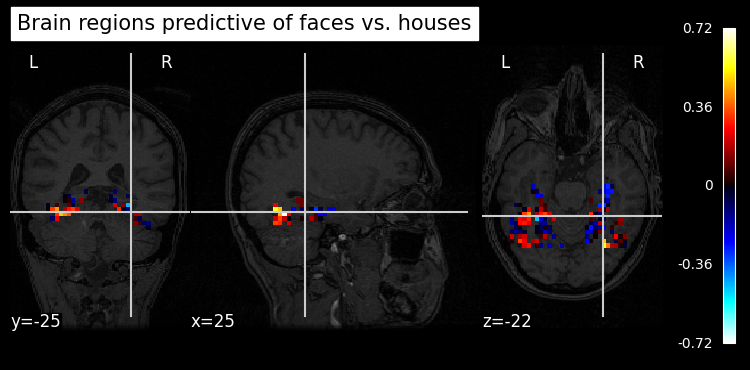

In [ ]:
# Training a Logistic Regression Classifier
clf = LogisticRegression()
clf.fit(X_train, y_train)

# Evaluating Model Performance
accuracy = clf.score(X_test, y_test)
print(f"Test Accuracy: {accuracy:.2f}")

# Cross-validation for robustness
cv_scores = cross_val_score(clf, X_pca, y, cv=5)
print(f"Cross-Validation Accuracy: {cv_scores.mean():.2f} ± {cv_scores.std():.2f}")

# Brain Activation Map
coef_img_pca = clf.coef_.ravel()
coef_img_pca_rescaled = pca.inverse_transform(coef_img_pca)   # Reshape to match 3D shape (x, y, z)
coef_img = nifti_masker.inverse_transform(coef_img_pca_rescaled)

plot_stat_map(coef_img, bg_img=haxby_dataset.anat[0], title="Brain regions predictive of faces vs. houses")
plt.show()

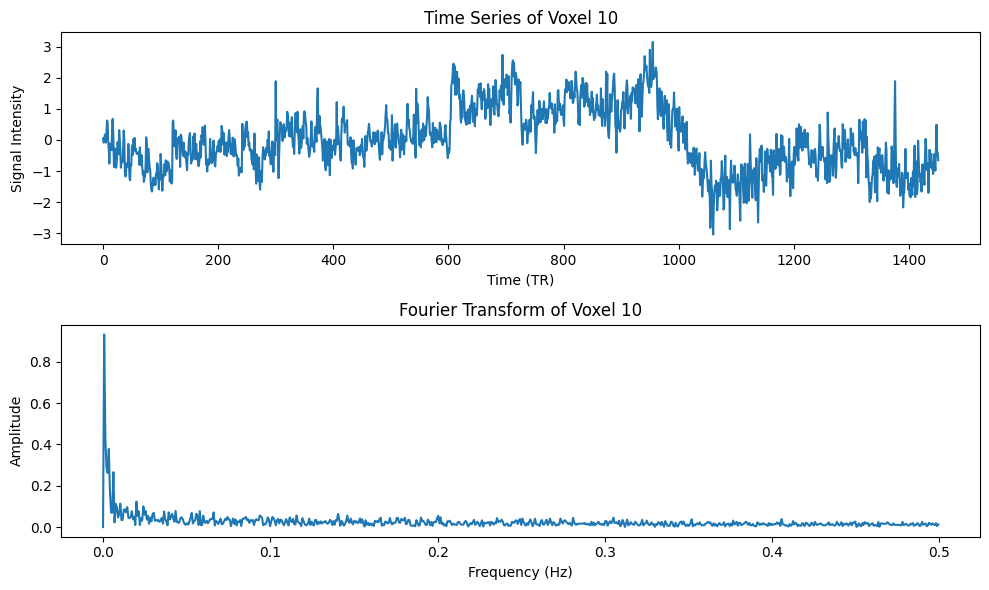

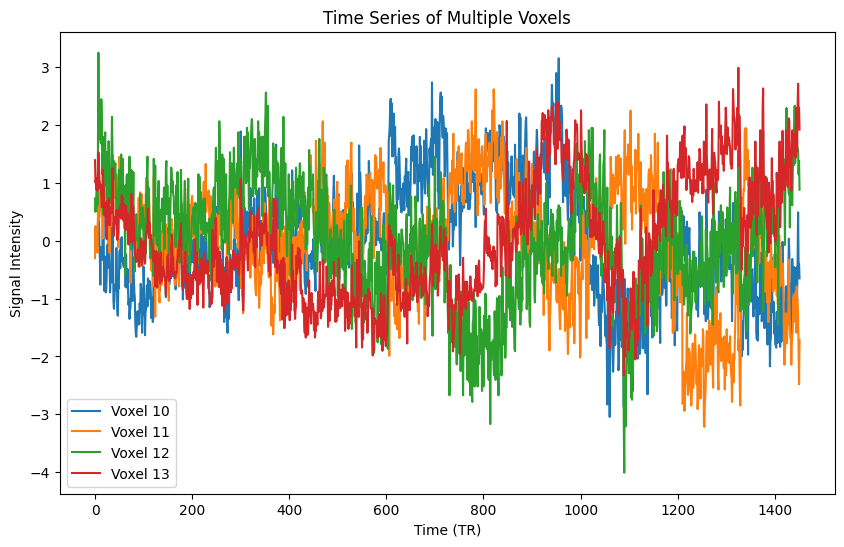

In [ ]:
# Masking the fMRI data 
nifti_masker = NiftiMasker(mask_img=mask_img, standardize=True)
fmri_data = nifti_masker.fit_transform(fmri_img)  # Shape: (timepoints, voxels)

# Extracting the time series for a specific voxel
voxel_idx = 10 
time_series_voxel = fmri_data[:, voxel_idx]

# Plot of the time series for that voxel
plt.figure(figsize=(10, 6))
plt.subplot(2, 1, 1)
plt.plot(time_series_voxel)
plt.title(f"Time Series of Voxel {voxel_idx}")
plt.xlabel("Time (TR)")
plt.ylabel("Signal Intensity")

# Fourier Transform on the time series
# Calculate the FFT
N = len(time_series_voxel)  # Number of data points
T = 1.0  # Sampling interval (time per TR, in seconds)
yf = fft(time_series_voxel)  # Fourier Transform of the signal
xf = fftfreq(N, T)[:N // 2]  # Frequency bins (only positive frequencies)

# Plot of the Fourier Transform (Frequency Spectrum)
plt.subplot(2, 1, 2)
plt.plot(xf, 2.0 / N * np.abs(yf[:N // 2]))  # Amplitude Spectrum
plt.title(f"Fourier Transform of Voxel {voxel_idx}")
plt.xlabel("Frequency (Hz)")
plt.ylabel("Amplitude")

plt.tight_layout()
plt.show()

plt.figure(figsize=(10, 6))
for i in range(10,14,1):
    plt.plot(fmri_data[:, i], label=f"Voxel {i}")
plt.title("Time Series of Multiple Voxels")
plt.xlabel("Time (TR)")
plt.ylabel("Signal Intensity")
plt.legend(loc='best')
plt.show()

In [54]:
labels = (labels == 'face')  # Convert to binary labels (face vs non-face)

# Step 3: Train-test split (80% training, 20% testing)
X_train, X_test, y_train, y_test = train_test_split(fmri_data, labels, test_size=0.2, random_state=42)

# Step 4: Logistic Regression (Linear Classifier)
clf_lr = LogisticRegression(max_iter=1000)
clf_lr.fit(X_train, y_train)

# Step 5: Random Forest (Non-Linear Classifier)
clf_rf = RandomForestClassifier(n_estimators=100)
clf_rf.fit(X_train, y_train)

# Step 6: Predictions and Evaluation for Logistic Regression
predictions_lr = clf_lr.predict(X_test)
print("Logistic Regression Evaluation:")
print(confusion_matrix(y_test, predictions_lr))
print(classification_report(y_test, predictions_lr))

# Step 7: Predictions and Evaluation for Random Forest
predictions_rf = clf_rf.predict(X_test)
print("Random Forest Evaluation:")
print(confusion_matrix(y_test, predictions_rf))
print(classification_report(y_test, predictions_rf))

Logistic Regression Evaluation:
[[272   0]
 [  2  17]]
              precision    recall  f1-score   support

       False       0.99      1.00      1.00       272
        True       1.00      0.89      0.94        19

    accuracy                           0.99       291
   macro avg       1.00      0.95      0.97       291
weighted avg       0.99      0.99      0.99       291

Random Forest Evaluation:
[[272   0]
 [ 18   1]]
              precision    recall  f1-score   support

       False       0.94      1.00      0.97       272
        True       1.00      0.05      0.10        19

    accuracy                           0.94       291
   macro avg       0.97      0.53      0.53       291
weighted avg       0.94      0.94      0.91       291

